In [ ]:
import math
import pylab as plt
import random

In [ ]:
def y_values(x):
  fraction = math.e ** (x)
  fraction = fraction/((x+1)**(x+1))
  return fraction**100

In [ ]:
def plot():
  cur_index = 0
  x = []
  y = []
  for i in range(100):
    cur_index += 0.01
    cur_index = round(cur_index,3)
    x.append(cur_index)
  for i in x:
    y.append(y_values(i))
  plt.plot(x,y)
  plt.title("Chernoff Bounds as Alpha Increases")
  plt.xlabel("Alpha")
  plt.ylabel("Max Bound")
  return x,y

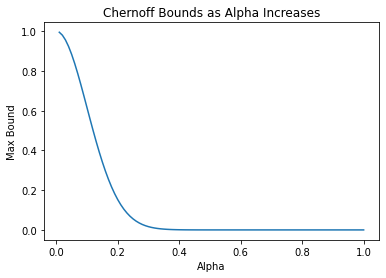

In [ ]:
theory = plot()

In [ ]:
def simulate_balls_and_bins(balls,bins):
  bins_dict_to_balls = {i:0 for i in range(1,bins+1)}
  for i in range(balls):
    random_bin = random.randint(1,bins)
    bins_dict_to_balls[random_bin] +=1 
  return bins_dict_to_balls

In [ ]:
def count_max_bound_prob(bins,simulation,max_bound):
  vals = list(simulation.values())
  count_above_bound = 0
  for i in vals:
    if i > max_bound:
      count_above_bound += 1
  return count_above_bound/bins

In [ ]:
def plot_simulation_overloaded(tasks, servers, trials):
  cur_index = 0
  x = []
  y = []
  for i in range(100):
    cur_index += 0.01
    cur_index = round(cur_index,3)
    x.append(cur_index)
  for i in x:
    max_bound = 100 * (i+1)
    average_probability = 0
    for i in range(trials):
      simulation = simulate_balls_and_bins(tasks,servers)
      probability_sim = count_max_bound_prob(servers,simulation,max_bound)
      average_probability += probability_sim
    average_probability = average_probability / trials
    y.append(average_probability)
  plt.plot(x,y,'r')
  plt.title("Simulation of Overload Probability")
  plt.xlabel("Alpha")
  plt.ylabel("Probabiilty")
  return x,y

In [ ]:
count_max_bound_prob(5,{1:2,3:4,4:5},2)

0.4

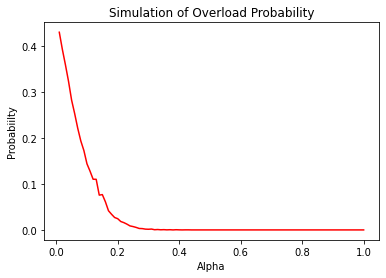

In [ ]:
simulation = plot_simulation_overloaded(100000,1000,7)

In [ ]:
def plot_theory_probability(tasks,servers,trials):
  x_1,y_1 = plot_simulation_overloaded(tasks, servers, trials)
  x_2,y_2 = plot()
  plt.plot(x_1,y_1,label="Simulation")
  plt.plot(x_2,y_2,label="Chernoff Bound")
  plt.legend()
  plt.xlabel("Alpha")
  plt.title("Simulation versus Theory")
  plt.ylabel("Probability")

In [ ]:
def plot_theory_probability_2(tasks,servers,trials):
  x_1,y_1 = plot_simulation_overloaded(tasks, servers, trials)
  x_2,y_2 = plot()
  plt.plot(x_1,y_1,label="Simulation")
  plt.plot(x_2,y_2,label="Theory")
  plt.xlabel("Alpha")
  plt.title("Simulation versus Theory")
  plt.ylabel("Probability")
  plt.xlim(0.2,1)
  plt.ylim(0,0.2)

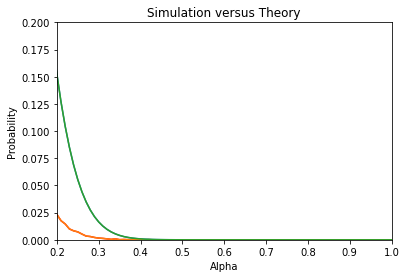

In [ ]:
plot_theory_probability_2(100000,1000,7)

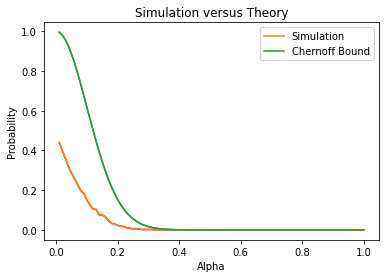

In [ ]:
plot_theory_probability(100000,1000,7)

#Overload

In [ ]:
def y_values_2(x):
  fraction = math.e ** (-x)
  fraction = fraction/((1-x)**(1-x))
  return fraction**100

def plot_2():
  cur_index = 0
  x = []
  y = []
  for i in range(100):
    cur_index += 0.01
    cur_index = round(cur_index,3)
    x.append(cur_index)
  for i in x:
    y.append(y_values_2(i))
  plt.plot(x,y)
  plt.title("Chernoff Bounds as Alpha Increases")
  plt.xlabel("Alpha")
  plt.ylabel("Max Bound")
  return x,y

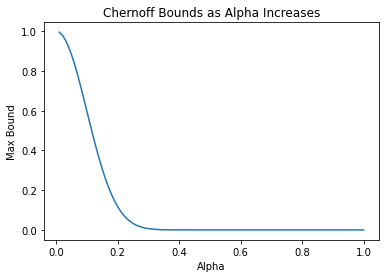

In [ ]:
theory = plot_2()

In [ ]:
def count_max_bound_prob_under(bins,simulation,max_bound):
  vals = list(simulation.values())
  count_above_bound = 0
  for i in vals:
    if i < max_bound:
      count_above_bound += 1
  return count_above_bound/bins

In [ ]:
def plot_simulation_underloaded(tasks, servers, trials):
  cur_index = 0
  x = []
  y = []
  for i in range(100):
    cur_index += 0.01
    cur_index = round(cur_index,3)
    x.append(cur_index)
  for i in x:
    max_bound = 100 * (1-i)
    average_probability = 0
    for i in range(trials):
      simulation = simulate_balls_and_bins(tasks,servers)
      probability_sim = count_max_bound_prob_under(servers,simulation,max_bound)
      average_probability += probability_sim
    average_probability = average_probability / trials
    y.append(average_probability)
  plt.plot(x,y,'r')
  plt.title("Simulation of Overload Probability")
  plt.xlabel("Alpha")
  plt.ylabel("Probabiilty")
  return x,y

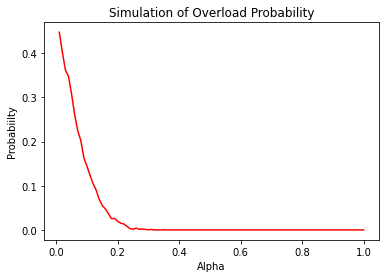

In [ ]:
simulation = plot_simulation_underloaded(100000,1000,2)

In [ ]:
def plot_theory_probability_under(tasks,servers,trials):
  x_1,y_1 = plot_simulation_underloaded(tasks, servers, trials)
  x_2,y_2 = plot_2()
  plt.plot(x_1,y_1,label="Simulation")
  plt.plot(x_2,y_2,label="Chernoff Bound")
  plt.xlabel("Alpha")
  plt.legend()
  plt.title("Simulation versus Theory: Smaller Than Mean")
  plt.ylabel("Probability")

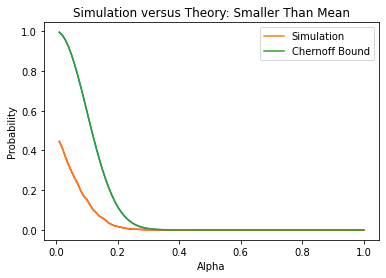

In [ ]:
plot_theory_probability_under(100000,1000,7)